# Week 7 · Task C — Make one chart interactive, and write the contract
**Chart chosen: Task B chart 1** (daily boardings by mode) — the one with a time axis, so it carries the two traps the brief names: *a zoom into the partial final period* and *a zoom onto the 14-day gap*.

* **Primary:** Plotly (installed here) → `partC_interactive.html` (self-contained, open in any browser) and in the notebook below.
* **No-install fallback:** `dashlib.LinkedBrush` on Task B chart 4, linked to a district panel that shows the **3.096× double count** the moment you brush — tested headlessly with `simulate()`.
* **Static default state:** `partC_default.png`. **Contract:** `partC_contract.md`.

In [1]:
import sys, os
from pathlib import Path
def _find_root():
    here = Path.cwd()
    for p in [here, here / "week7" / "assignments", here.parent / "assignments"]:
        if (p / "dashlib.py").exists() and (p / "data" / "ridership_daily.csv").exists():
            return p
    raise FileNotFoundError("Put this notebook in week7/assignments/ (next to dashlib.py) and run it from there.")
ROOT = _find_root(); os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("working in", ROOT)

working in c:\Users\Nas Graphy\Downloads\Data-Visualization\Week 7


In [2]:
import numpy as np, pandas as pd, textwrap
import matplotlib; import matplotlib.pyplot as plt
import vizlib, tslib, geolib, dashlib
from vizlib import PALETTE
vizlib.style_defaults()
pd.set_option("display.width", 200)
CLEAN = Path("clean")
need = ["district_transit_clean.csv", "routes_clean.csv", "ridership_calendar.csv", "fare_revenue_clean.csv"]
assert all((CLEAN / f).exists() for f in need), "Run partA_process.ipynb first: it writes clean/"

reg = pd.read_csv(CLEAN / "district_transit_clean.csv")
rt = pd.read_csv(CLEAN / "routes_clean.csv")
cal = pd.read_csv(CLEAN / "ridership_calendar.csv", parse_dates=["date"])
fr = pd.read_csv(CLEAN / "fare_revenue_clean.csv")
feats = geolib.read_geojson("data/regions.geojson")
parts = fr[~fr.is_total]                                  # the 216 real parts; the 72 subtotals are out
COMPLETE_END = "2026-08-31"                               # 2026-09 is a partial month (Bus, Ferry stopped filing 22 Sep)
MODES = ["Metro", "BRT", "Bus", "Ferry"]
# one hue per mode, everywhere. Ferry's 4th hue is below 3:1 contrast on white, so every mode is ALSO direct-labelled.
MODE_COL = {"Metro": PALETTE["series"][0], "BRT": PALETTE["series"][2], "Bus": PALETTE["series"][1], "Ferry": PALETTE["series_4th"]}
filed = cal[cal.status == "filed"]

def wrap(s, n=160): return "\n".join(textwrap.wrap(s, n))
def frame(fig, title, caption, top=0.84):
    """Finding as the title, the decision it supports as a one-line caption."""
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
    fig.text(0.01, 0.995 - 0.075 * (6.0 / fig.get_size_inches()[1]), caption, ha="left", va="top", fontsize=9.5, style="italic", color=PALETTE["ink_soft"])
    fig.subplots_adjust(top=top)

In [3]:
import json
# ---- the facts the contract must be honest about -------------------------------------------------
ov = dashlib.overlap_factor(rt, "route_id", "districts_served", "boardings_annual")
assert not cal[cal.status == "filed"].duplicated(["date", "mode"]).any()          # a mode filter is EXCLUSIVE in this view
nf = cal[cal.status == "not_filed"].sort_values(["mode", "date"])
runs = []
for mo, g in nf.groupby("mode"):
    rid = (g.date.diff().dt.days != 1).cumsum()
    for _, h in g.groupby(rid): runs.append((mo, h.date.min(), h.date.max(), len(h)))
gap = max(runs, key=lambda r: r[3]); print("longest gap:", gap[0], gap[1].date(), "->", gap[2].date(), gap[3], "days")
print(f"overlap_factor (routes by district): {ov['factor']:.3f}x  ({ov['units_multi']} of {ov['units']} routes serve >1 district)")

wide = cal.pivot(index="date", columns="mode", values="boardings")[MODES]
nfiled = (wide.notna().astype(int)).rolling(7, center=True, min_periods=1).sum()
sm = wide.rolling(7, center=True, min_periods=5).mean() / 1000
print("window days filed (min over the series) :", int(nfiled.min().min()))

longest gap: Metro 2026-02-09 -> 2026-02-22 14 days
overlap_factor (routes by district): 3.096x  (28 of 36 routes serve >1 district)
window days filed (min over the series) : 0


## 1 · The Plotly view

In [4]:
import plotly.graph_objects as go, plotly.io as pio
HAS_PLOTLY = dashlib.has_plotly(); print("plotly available:", HAS_PLOTLY)
if HAS_PLOTLY:
    fig = go.Figure()
    for mo in MODES:
        fig.add_trace(go.Scatter(x=sm.index, y=sm[mo], name=mo, mode="lines", line=dict(color=MODE_COL[mo], width=2.4), connectgaps=False,
            customdata=nfiled[mo].values, hovertemplate=mo + ": %{y:,.0f}k boardings/day (7-day mean, %{customdata:.0f} of 7 days filed)<extra></extra>"))
    # the two places a zoom can mislead, drawn permanently (a control must not be able to hide them)
    fig.add_vrect(x0="2026-09-01", x1="2026-09-30", fillcolor="#DFE6EE", opacity=0.6, line_width=0, layer="below",
                  annotation_text="PARTIAL month: Bus & Ferry stopped filing 22 Sep", annotation_position="top left", annotation_font_size=10)
    fig.add_vrect(x0=gap[1], x1=gap[2], fillcolor="#DFE6EE", opacity=0.6, line_width=0, layer="below",
                  annotation_text="Metro not filed (14 d)", annotation_position="bottom left", annotation_font_size=10)
    def rng(a, b): return dict(method="relayout", args=[{"xaxis.range": [a, b], "xaxis.autorange": False}])
    fig.update_layout(
        template="simple_white", height=560, margin=dict(l=70, r=30, t=110, b=40), hovermode="x unified",
        title=dict(text="<b>Metro boardings per day nearly doubled while Bus fell</b><br><sup>Boardings (legs, not journeys), 7-day mean of filed days. Click a legend entry to hide a mode, double-click to isolate; drag or use the slider to zoom.</sup>", x=0.01),
        yaxis=dict(title="boardings per day (thousands)", rangemode="tozero", gridcolor="#DFE6EE"),
        xaxis=dict(rangeslider=dict(visible=True, thickness=0.07), gridcolor="#DFE6EE", range=["2025-04-01", "2026-09-30"]),
        legend=dict(title="mode (click / double-click)", orientation="h", y=1.0, x=0.0, yanchor="bottom"),
        updatemenus=[dict(type="buttons", direction="right", x=1.0, xanchor="right", y=1.17, yanchor="top", buttons=[
            dict(label="Reset: full period", **rng("2025-04-01", "2026-09-30")),
            dict(label="Complete months only", **rng("2025-04-01", "2026-08-31")),
            dict(label="Last 3 complete months", **rng("2026-06-01", "2026-08-31"))])])
    POST = """
var gd = document.getElementById('{plot_id}');
var warn = document.createElement('div'); warn.style.cssText = 'font:13px sans-serif;margin:4px 14px;color:#16202E;min-height:3em';
gd.parentNode.appendChild(warn);
var P=[Date.parse('2026-09-01'),Date.parse('2026-09-30')], G=[Date.parse('2026-02-09'),Date.parse('2026-02-22')];
function t(s){ return Date.parse(String(s).replace(' ','T')); }
function msg(){ var r=gd.layout.xaxis.range, a=t(r[0]), b=t(r[1]), m=[];
  if(b>=P[0] && a<=P[1]) m.push('This window includes September 2026, a PARTIAL month: Bus and Ferry stopped filing on 22 Sep, so their lines END. Boardings did not fall to zero.');
  if(b>=G[0] && a<=G[1]) m.push('This window includes 9-22 Feb 2026: Metro filed nothing. The break is missing data, not zero boardings.');
  m.push('Hidden modes are removed from view only, not from the data. Modes are separate rows, so the visible modes add up to the network (never mix with journeys).');
  warn.innerHTML = m.join('<br>'); }
gd.on('plotly_relayout', msg); gd.on('plotly_restyle', msg); msg();
"""
    fig.write_html("partC_interactive.html", include_plotlyjs=True, post_script=POST, config=dict(displaylogo=False, doubleClick="reset+autosize"))
    print("wrote partC_interactive.html  (%.1f MB)" % (Path("partC_interactive.html").stat().st_size / 1e6))
    pio.renderers.default = "notebook_connected"
    fig.show()

plotly available: True
wrote partC_interactive.html  (4.9 MB)


## 2 · Static PNG of the default state — what a reader sees before touching anything

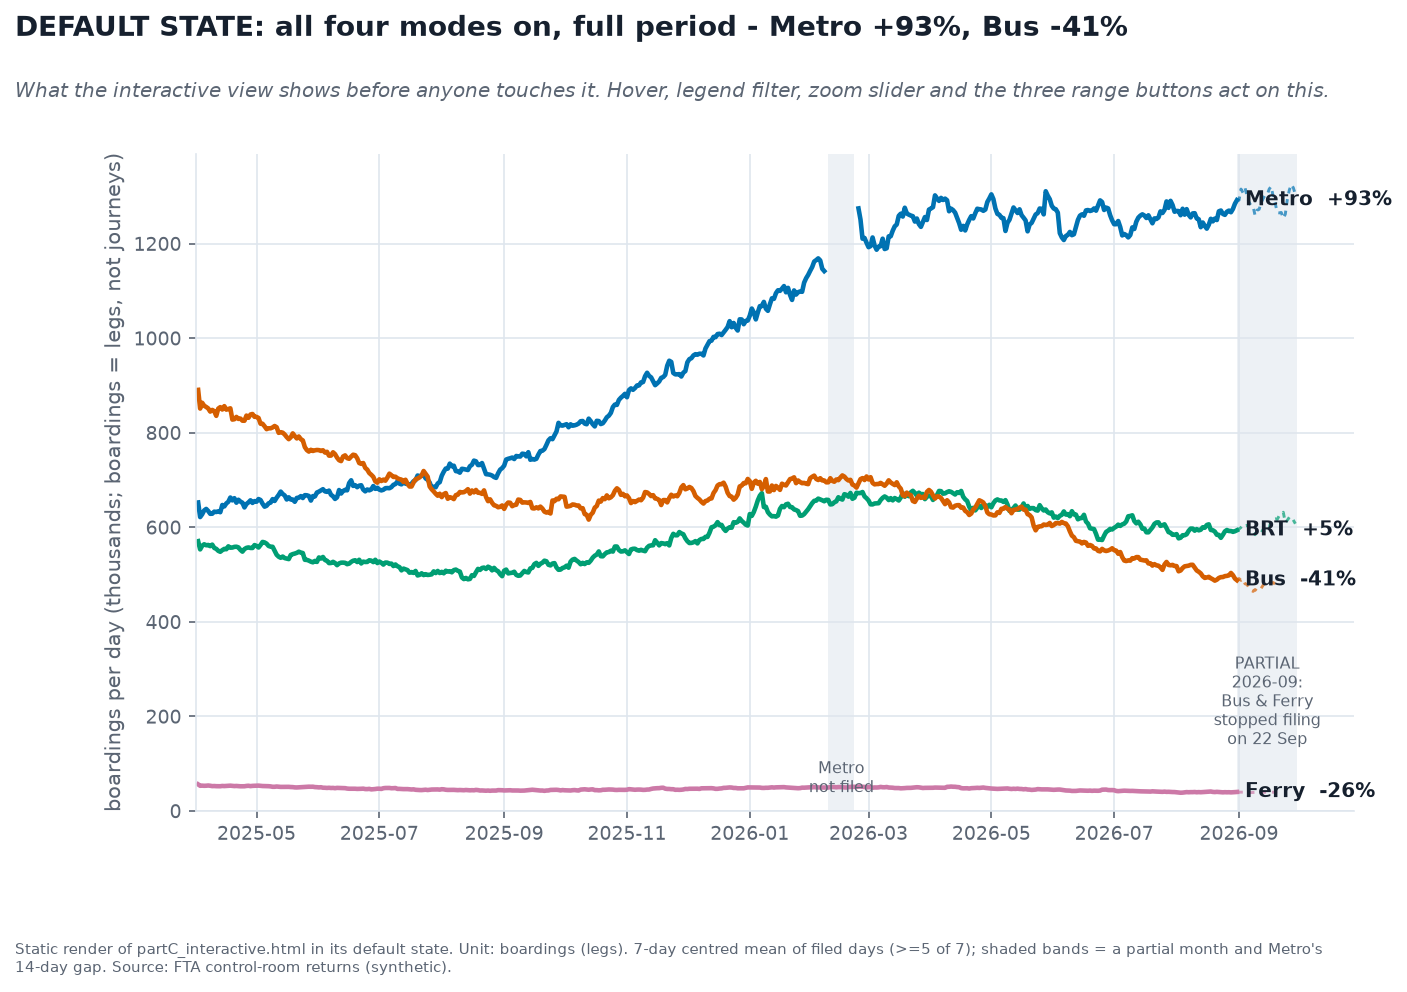

In [5]:
end = pd.Timestamp(COMPLETE_END)
m = filed[filed.date <= COMPLETE_END].assign(mo=lambda d: d.date.dt.to_period("M")).groupby(["mo", "mode"]).boardings.mean().unstack()
chg = (m.iloc[-1] / m.iloc[0] - 1) * 100
fig, ax = plt.subplots(figsize=(10.5, 6.0))
for mo in MODES:
    s = sm[mo]
    ax.plot(s[s.index <= end].index, s[s.index <= end], color=MODE_COL[mo], lw=2.2)
    ax.plot(s[s.index >= end].index, s[s.index >= end], color=MODE_COL[mo], lw=1.4, ls=(0, (2, 2)), alpha=0.7)
    ax.text(end + pd.Timedelta(days=4), s[s.index <= end].dropna().iloc[-1], f"{mo}  {chg[mo]:+.0f}%", fontsize=9.5, va="center", fontweight="bold")
ax.axvspan(end, wide.index.max(), color=PALETTE["grid"], alpha=0.55, lw=0)
ax.axvspan(gap[1], gap[2], color=PALETTE["grid"], alpha=0.55, lw=0); ax.text(gap[1] + (gap[2] - gap[1]) / 2, 40, "Metro\nnot filed", fontsize=7.5, ha="center", color=PALETTE["ink_soft"])
ax.text(end + pd.Timedelta(days=15), 330, "PARTIAL\n2026-09:\nBus & Ferry\nstopped filing\non 22 Sep", fontsize=7.5, color=PALETTE["ink_soft"], va="top", ha="center")
ax.set_ylim(0, None); ax.set_xlim(wide.index.min(), wide.index.max() + pd.Timedelta(days=28)); ax.set_ylabel("boardings per day (thousands; boardings = legs, not journeys)")
frame(fig, f"DEFAULT STATE: all four modes on, full period - Metro {chg['Metro']:+.0f}%, Bus {chg['Bus']:.0f}%",
      "What the interactive view shows before anyone touches it. Hover, legend filter, zoom slider and the three range buttons act on this.")
fig.subplots_adjust(right=0.86)
vizlib.save_fig(fig, "partC_default.png", note=wrap("Static render of partC_interactive.html in its default state. Unit: boardings (legs). 7-day centred mean of filed days (>=5 of 7); shaded bands = a partial month and Metro's 14-day gap. Source: FTA control-room returns (synthetic).", 175))
plt.show()

## 3 · The no-install route: `dashlib.LinkedBrush` on Task B chart 4, linked to a district panel
Drag a rectangle on the scatter (needs `%matplotlib widget` in a notebook, or any interactive backend). The right panel shows the **districts those routes are credited to** — and says, on the figure, what happens if you add the bars up. Here it is driven with `simulate()`, which is how a brush is tested with no mouse.

selected: 11 routes; reset returns 33 of 33


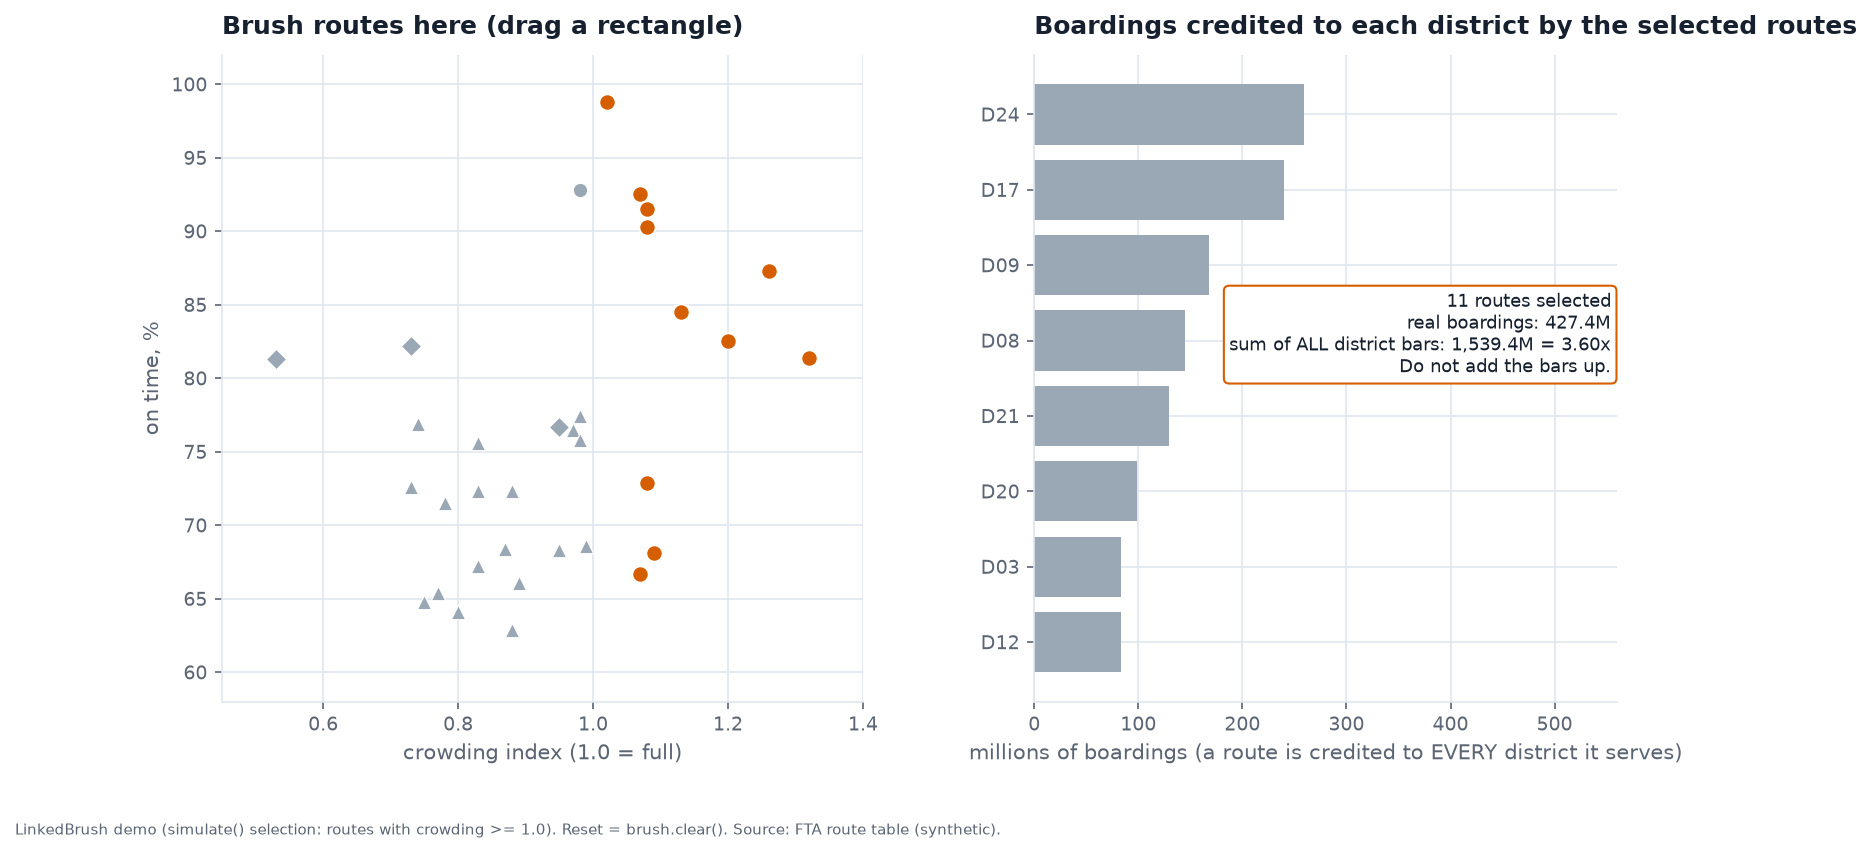

In [6]:
r4 = rt.dropna(subset=["punctuality_pct"]).reset_index(drop=True)
fig = plt.figure(figsize=(12, 5.6)); gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1], wspace=0.28)
axs, axd = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
for mo, mk in zip(MODES, vizlib.MARKERS):
    g = r4[r4["mode"] == mo]; axs.scatter(g.crowding_index, g.punctuality_pct, s=48, marker=mk, color=PALETTE["muted"], edgecolor="white", lw=0.6, zorder=3)
axs.set_xlabel("crowding index (1.0 = full)"); axs.set_ylabel("on time, %"); axs.set_title("Brush routes here (drag a rectangle)")
state = {"hi": None}

def repaint(mask):
    if state["hi"] is not None: state["hi"].remove(); state["hi"] = None                  # take the old highlight off first
    sel = r4[mask.values]
    if len(sel) < len(r4):
        state["hi"] = axs.scatter(sel.crowding_index, sel.punctuality_pct, s=60, color=PALETTE["highlight"], edgecolor="white", lw=0.8, zorder=6)
    axd.clear(); axd.set_title("Boardings credited to each district by the selected routes")
    o = dashlib.overlap_factor(sel, "route_id", "districts_served", "boardings_annual")
    top = (o["by_part"] / 1e6).head(8)
    axd.barh(top.index[::-1], top.values[::-1], color=PALETTE["muted"]); axd.set_xlabel("millions of boardings (a route is credited to EVERY district it serves)")
    axd.set_xlim(0, 560)
    axd.text(0.99, 0.5, f"{len(sel)} routes selected\nreal boardings: {o['true_total']/1e6:,.1f}M\nsum of ALL district bars: {o['attributed_total']/1e6:,.1f}M = {o['factor']:.2f}x\nDo not add the bars up.",
             transform=axd.transAxes, ha="right", va="bottom", fontsize=8.5, color=PALETTE["ink"], bbox=dict(boxstyle="round", fc="white", ec=PALETTE["highlight"]))
    fig.canvas.draw_idle()

brush = dashlib.LinkedBrush(axs, r4, "crowding_index", "punctuality_pct", on_select=repaint)
axs.set_xlim(0.45, 1.4); axs.set_ylim(58, 102)
brush.simulate((1.0, 60, 1.4, 100))                       # "brush every route at or over capacity"
sel_n = int(brush.mask.sum()); print("selected:", sel_n, "routes; reset returns", int(brush.clear().sum()), "of", len(r4))
brush.simulate((1.0, 60, 1.4, 100))                       # leave the figure in the selected state for the PNG
vizlib.save_fig(fig, "partC_brush_demo.png", note="LinkedBrush demo (simulate() selection: routes with crowding >= 1.0). Reset = brush.clear(). Source: FTA route table (synthetic).")
plt.show()

## 4 · The contract — `partC_contract.md`

In [7]:
gap_days = gap[3]
contract = f"""# Task C — interaction contract

**View:** `partC_interactive.html` (Plotly; built by `partC_interactive.ipynb`) — Task B chart 1, daily boardings by mode. Static default: `partC_default.png`. No-install fallback: `LinkedBrush` demo, `partC_brush_demo.png`.

## The default state
Before anyone touches it the view says one sentence: **Metro boardings per day have nearly doubled since April 2025 while Bus has fallen by about two-fifths** — all four modes, the full period, with the partial month and Metro's {gap_days}-day gap already shaded.

## The controls
| Control | What it changes | What it does **not** change | Way back |
|---|---|---|---|
| Legend click / double-click | Which modes are *visible* (double-click isolates one) | The data, the smoothing, the unit, the shaded bands | Click again; double-click the legend again to show all; "Reset" button |
| Zoom by drag, or the range slider | The visible date window and the y-scale | The 7-day smoothing; the bands; the values | **"Reset: full period"** button, double-click on the plot, or the modebar home icon |
| Three range buttons (full / complete months / last 3 complete months) | The visible window only | Everything else | They *are* the reset: "Reset: full period" |
| Hover | Reads one date: value and how many of the 7 days in that window were actually filed | Nothing | — |

Always on, not controllable: the **partial September 2026** band, the **Metro 9-22 Feb** band, the unit "boardings (legs), not journeys", and a live warning line under the chart that names any of those two periods that the current window includes.

## The thing the control must not invite
**Two wrong conclusions were easy, and I dealt with both.**
1. *"Bus and Ferry collapsed in September / Metro fell to zero in February."* A date zoom onto either window makes a missing-data hole look like a crash. I did not make it impossible to zoom there — I made it impossible to misread: lines **break** (never drop to zero), the periods are shaded and labelled permanently, and the warning line under the chart says "partial month / missing data, not zero" whenever the window touches them.
2. *"Add up the filtered views."* A mode filter is safe in this chart — every row is one mode on one day, so the visible modes add up to the network (checked: no duplicated date-mode). It would **not** be safe on `routes.csv` by district: a route is credited to every district it serves, and summing the filtered district views gives **{ov['factor']:.3f}×** the true total ({ov['units_multi']} of {ov['units']} routes serve more than one district). So the district view is not offered as a filter on the Plotly chart; in the `LinkedBrush` demo the sum and its multiple are printed *on the figure* beside the bars.
"""
Path("partC_contract.md").write_text(contract, encoding="utf-8"); print(len(contract.split()), "words")

466 words
